<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/Latihan_BAB7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import library dasar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import dataset dan modul machine learning
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Import model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Import metrik evaluasi
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standarisasi fitur (Sangat penting untuk Logistic Regression dan KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data berhasil dimuat dan dibagi.")
print(f"Total data: {X.shape[0]}, Train: {X_train.shape[0]}, Test: {X_test.shape[0]}")

Data berhasil dimuat dan dibagi.
Total data: 569, Train: 455, Test: 114


=== LOGISTIC REGRESSION ===
Confusion Matrix:
 [[41  1]
 [ 1 71]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


=== DECISION TREE ===
Confusion Matrix:
 [[39  3]
 [ 6 66]]

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.93      0.90        42
           1       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



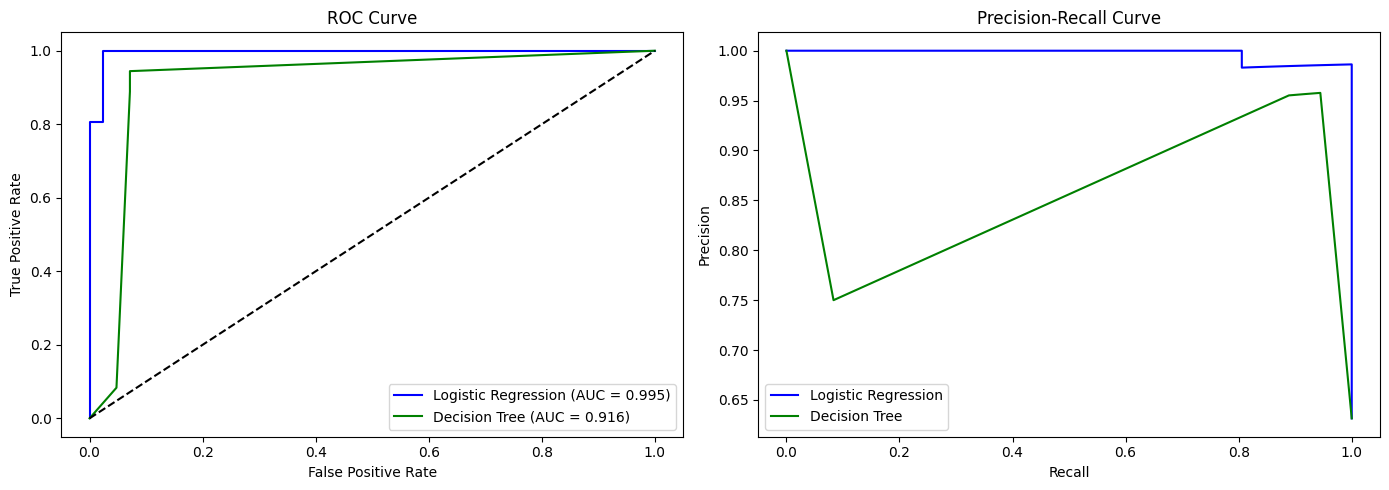

In [2]:
# Inisialisasi model
log_reg = LogisticRegression(random_state=42)
dec_tree = DecisionTreeClassifier(max_depth=5, random_state=42)

# Latih model
log_reg.fit(X_train_scaled, y_train)
dec_tree.fit(X_train_scaled, y_train)

# Prediksi
y_pred_log = log_reg.predict(X_test_scaled)
y_pred_tree = dec_tree.predict(X_test_scaled)

# Prediksi Probabilitas (untuk ROC dan PR Curve)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]
y_prob_tree = dec_tree.predict_proba(X_test_scaled)[:, 1]

# --- 1. Confusion Matrix & Classification Report ---
print("=== LOGISTIC REGRESSION ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))

print("\n=== DECISION TREE ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tree))
print("\nClassification Report:\n", classification_report(y_test, y_pred_tree))

# --- 2. Visualisasi ROC dan PR Curve ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot ROC Curve
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
roc_auc_log = auc(fpr_log, tpr_log)

fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)
roc_auc_tree = auc(fpr_tree, tpr_tree)

axes[0].plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {roc_auc_log:.3f})', color='blue')
axes[0].plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {roc_auc_tree:.3f})', color='green')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# Plot Precision-Recall Curve
precision_log, recall_log, _ = precision_recall_curve(y_test, y_prob_log)
precision_tree, recall_tree, _ = precision_recall_curve(y_test, y_prob_tree)

axes[1].plot(recall_log, precision_log, label='Logistic Regression', color='blue')
axes[1].plot(recall_tree, precision_tree, label='Decision Tree', color='green')
axes[1].set_title('Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

In [3]:
# 1-3. Import sudah dilakukan di cell pertama
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 4. Definisikan model list
model_list = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

# 8. Inisialisasi Stratified k-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 9. Looping untuk evaluasi
print("=== Perbandingan Model (5-Fold Stratified CV) ===")
for nama, model in model_list.items():
    # Menggunakan data yang sudah di-scale
    skor = cross_val_score(model, X_train_scaled, y_train, cv=skf, scoring="f1")

    # 12. Print hasil
    print(f"{nama}: F1 rata-rata = {skor.mean():.3f} (+/- {skor.std():.3f})")

# 14. Kesimpulan (Akan berbeda tergantung hasil running, namun biasanya seperti ini)
print("\n=== KESIMPULAN ===")
print("Berdasarkan hasil di atas, kita dapat melihat nilai rata-rata F1 dan standar deviasinya.")
print("- Model dengan F1 rata-rata tertinggi adalah model yang paling BAIK.")
print("- Model dengan nilai standar deviasi (+/-) terkecil adalah model yang paling STABIL/konsisten.")

=== Perbandingan Model (5-Fold Stratified CV) ===
Logistic Regression: F1 rata-rata = 0.983 (+/- 0.008)
Decision Tree: F1 rata-rata = 0.937 (+/- 0.011)
KNN: F1 rata-rata = 0.969 (+/- 0.009)

=== KESIMPULAN ===
Berdasarkan hasil di atas, kita dapat melihat nilai rata-rata F1 dan standar deviasinya.
- Model dengan F1 rata-rata tertinggi adalah model yang paling BAIK.
- Model dengan nilai standar deviasi (+/-) terkecil adalah model yang paling STABIL/konsisten.
